# Text Splitters in LangChain

First we load a web page to split, then go through the splitters used most in industry.

### Load the data
- `WebBaseLoader` - downloads the page and returns its **text**
- `AsyncChromiumLoader` - opens the page in a headless Chromium and returns the **raw HTML** (needed for the HTML splitter).
  Needs Playwright: `pip install playwright` and `playwright install chromium`. In Jupyter use `await ... .aload()`.

In [1]:
from langchain_community.document_loaders import WebBaseLoader, AsyncChromiumLoader

url = "https://en.wikipedia.org/wiki/Lego_Vidiyo"

data = WebBaseLoader(url).load()                       # text
data2 = await AsyncChromiumLoader([url]).aload()       # raw HTML

print(len(data[0].page_content), "chars of text,", len(data2[0].page_content), "chars of HTML")

/var/folders/hl/d4cjwg3x7bs25zps_ddj_tzw0000gn/T/ipykernel_33350/1206418591.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import WebBaseLoader, AsyncChromiumLoader
/Users/sriharshamadireddy/Desktop/Personal/Learning/DataScience/genai/venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
USER_AGENT environment variable not set, consider setting it to identify your requests.
USER_AGENT environment variable not set, consider setting it to identify your requests.


16225 chars of text, 399869 chars of HTML


## Text Splitters

LLMs and embedding models have size limits, and retrieval works best on small focused pieces of text.
A **text splitter** breaks a big `Document` into smaller chunks (each one is still a `Document`, and keeps the parent's metadata).

Two settings you will see everywhere:
- **`chunk_size`** - the maximum size of a chunk (in characters by default, or tokens if you ask for it)
- **`chunk_overlap`** - how much text is repeated between neighbouring chunks, so a sentence cut at the boundary isn't lost. Must be smaller than `chunk_size`.

Splitters used widely in industry:
1. `CharacterTextSplitter` - split on one separator
2. `RecursiveCharacterTextSplitter` - the default choice
3. Token based - `from_tiktoken_encoder`, `TokenTextSplitter`
4. Structure aware - Markdown, HTML, code, JSON
5. `SemanticChunker` - split where the meaning changes

In [2]:
from langchain_text_splitters import (
    CharacterTextSplitter,
    RecursiveCharacterTextSplitter,
    TokenTextSplitter,
    MarkdownHeaderTextSplitter,
    HTMLHeaderTextSplitter,
    RecursiveJsonSplitter,
    Language,
)

# small helper to look at the chunks
def show(chunks, n=3):
    print(f"Total chunks: {len(chunks)}\n")
    for i, chunk in enumerate(chunks[:n]):
        text = chunk.page_content if hasattr(chunk, "page_content") else chunk
        print(f"--- chunk {i} ({len(text)} chars) ---")
        print(text[:300])
        if hasattr(chunk, "metadata"):
            print("metadata:", chunk.metadata)
        print()

# the Wikipedia page we loaded with WebBaseLoader, cleaned up a little:
# collapse the long runs of blank lines and skip the menus before the article
import re
from langchain_core.documents import Document

text = re.sub(r"\n\s*\n+", "\n\n", data[0].page_content)
start = text.find("From Wikipedia")
text = text[start:] if start != -1 else text

clean_docs = [Document(page_content=text, metadata=data[0].metadata)]
print(len(text), "characters")

14832 characters


### 1. CharacterTextSplitter
Splits on **one separator** (default `"\n\n"`, i.e. paragraphs), then merges the pieces back together until `chunk_size` is reached.

Simple, but if one piece between separators is bigger than `chunk_size` it is **not** cut further - you get an oversized chunk and a warning.

In [3]:
characterTextSplitter = CharacterTextSplitter(
    separator="\n\n",
    chunk_size=500,
    chunk_overlap=50,
)

# expect "Created a chunk of size ... longer than 500" warnings: some paragraphs are bigger than chunk_size
chunks = characterTextSplitter.split_text(text)   # str  -> list[str]
show(chunks)

Created a chunk of size 5801, which is longer than the specified 500
Created a chunk of size 4072, which is longer than the specified 500
Created a chunk of size 2413, which is longer than the specified 500
Created a chunk of size 798, which is longer than the specified 500
Created a chunk of size 505, which is longer than the specified 500


Total chunks: 10

--- chunk 0 (98 chars) ---
From Wikipedia, the free encyclopedia

Discontinued product line and app created by the Lego Group

--- chunk 1 (5801 chars) ---
Lego VidiyoSubjectMusic videosLicensed fromUniversal Music GroupAvailabilityMarch 1, 2021; 5 years ago (2021-03-01)–January 31, 2022; 4 years ago (2022-01-31)Official website
Lego Vidiyo (stylised as VIDIYO) is a discontinued Lego theme and mobile app created by the Lego Group in collaboration with 

--- chunk 2 (72 chars) ---
↑ Abbreviation of Love, Laughter, and Music Always[17]

References[edit]



### 2. RecursiveCharacterTextSplitter (most used)
Tries a **list of separators in order**: `["\n\n", "\n", " ", ""]` - paragraphs first, then lines, then words, then characters.
It only goes to the next separator when a piece is still too big, so related text stays together as much as possible.

This is the recommended default for plain text. Typical settings: `chunk_size` 500-1000, `chunk_overlap` 10-20% of that.

- `split_text(str)` returns strings
- `split_documents(list[Document])` returns Documents and keeps the metadata
- `add_start_index=True` stores where each chunk starts in the original text (useful to put chunks back in order)

In [5]:
recursiveCharacterTextSplitter = RecursiveCharacterTextSplitter(
    chunk_size=500,
    chunk_overlap=50,
    add_start_index=True,
)

docs = recursiveCharacterTextSplitter.split_documents(clean_docs)   # Documents -> Documents
show(docs)


"""
With separator="\n\n", as in the notebook:

It cuts the text at every blank line, giving you paragraphs.
It merges paragraphs back together until adding the next one would go over chunk_size.
If a single paragraph is already bigger than chunk_size, it keeps that paragraph whole as one oversized chunk and logs the "Created a chunk of size 5801…" warning. It doesn't try lines, words or characters.
"""

Total chunks: 43

--- chunk 0 (98 chars) ---
From Wikipedia, the free encyclopedia

Discontinued product line and app created by the Lego Group
metadata: {'source': 'https://en.wikipedia.org/wiki/Lego_Vidiyo', 'title': 'Lego Vidiyo - Wikipedia', 'language': 'en', 'start_index': 0}

--- chunk 1 (485 chars) ---
Lego VidiyoSubjectMusic videosLicensed fromUniversal Music GroupAvailabilityMarch 1, 2021; 5 years ago (2021-03-01)–January 31, 2022; 4 years ago (2022-01-31)Official website
Lego Vidiyo (stylised as VIDIYO) is a discontinued Lego theme and mobile app created by the Lego Group in collaboration with 
metadata: {'source': 'https://en.wikipedia.org/wiki/Lego_Vidiyo', 'title': 'Lego Vidiyo - Wikipedia', 'language': 'en', 'start_index': 100}

--- chunk 2 (294 chars) ---
In July 2021, the Lego Group announced that the theme would go on hiatus while Lego researched ways to improve their play experiences. In January 2022, it was officially discontinued. The Lego Vidiyo app, which was avai

'\nWith separator="\n\n", as in the notebook:\n\nIt cuts the text at every blank line, giving you paragraphs.\nIt merges paragraphs back together until adding the next one would go over chunk_size.\nIf a single paragraph is already bigger than chunk_size, it keeps that paragraph whole as one oversized chunk and logs the "Created a chunk of size 5801…" warning. It doesn\'t try lines, words or characters.\n'

### 3. Token based splitters
Models count their limits in **tokens**, not characters (1 token is roughly 4 English characters).

- **`from_tiktoken_encoder`** - same splitter, but `chunk_size` is measured in tokens using OpenAI's `tiktoken`. Pass `encoding_name` or `model_name` to match your model.
- **`TokenTextSplitter`** - cuts purely by token count. Strict size, but can cut in the middle of a sentence.

In [ ]:
# Recursive splitter that measures size in tokens
tokenRecursiveSplitter = RecursiveCharacterTextSplitter.from_tiktoken_encoder(
    encoding_name="cl100k_base",
    chunk_size=100,      # 100 tokens, not characters
    chunk_overlap=10,
)
token_chunks = tokenRecursiveSplitter.split_text(text)
show(token_chunks, n=2)

### 3.a ) How RecursiveCharacterTextSplitter.from_tiktoken_encoder works internally

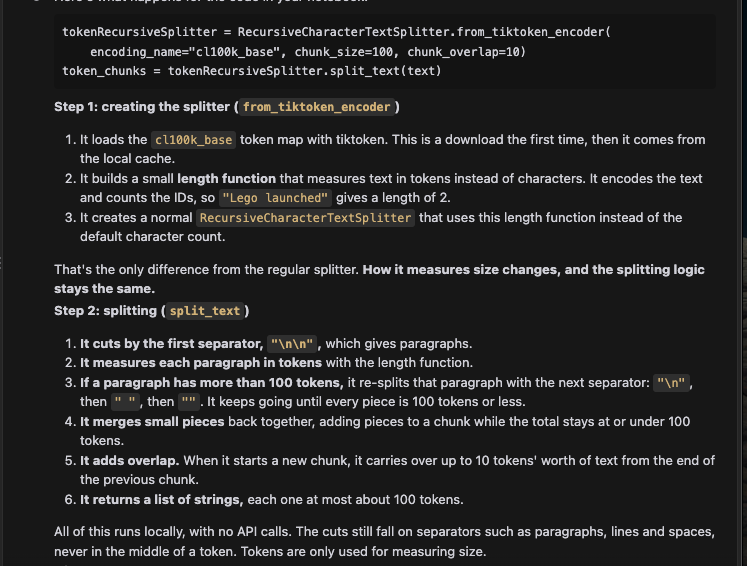

In [ ]:
tokenTextSplitter = TokenTextSplitter(
    encoding_name="cl100k_base",
    chunk_size=100,
    chunk_overlap=10,
)
show(tokenTextSplitter.split_text(text), n=2)

### 4. Structure aware splitters
Split on the document's own structure (headings, tags, functions) so each chunk is a real section.
The heading a chunk came from is saved in its **metadata**, which is very useful for retrieval and citations.

#### 4a. MarkdownHeaderTextSplitter

In [ ]:
markdown_text = """# LangChain
LangChain is a framework for building LLM apps.

## Document Loaders
Loaders read data from files, websites and databases.

## Text Splitters
Splitters break large documents into smaller chunks.

### Recursive splitter
The most commonly used splitter.
"""

markdownSplitter = MarkdownHeaderTextSplitter(
    headers_to_split_on=[("#", "h1"), ("##", "h2"), ("###", "h3")]
)
show(markdownSplitter.split_text(markdown_text), n=4)

#### 4b. HTMLHeaderTextSplitter
Same idea for HTML - splits on `<h1>`, `<h2>`, ... tags. Works directly on the **raw HTML** that `AsyncChromiumLoader` returned.

In [ ]:
htmlSplitter = HTMLHeaderTextSplitter(
    headers_to_split_on=[("h1", "h1"), ("h2", "h2"), ("h3", "h3")]
)

html_docs = htmlSplitter.split_text(data2[0].page_content)   # raw HTML of the Wikipedia page
show(html_docs)

HTML sections can be very long, so in practice you often **chain** splitters: split by structure first, then run the recursive splitter on the result so no chunk is too big. The header metadata is kept.

In [ ]:
html_chunks = recursiveCharacterTextSplitter.split_documents(html_docs)
show(html_chunks)

#### 4c. Code splitter
`RecursiveCharacterTextSplitter.from_language` uses language specific separators (`class`, `def`, ...) so functions and classes stay whole.
Supports Python, JS, TS, Java, Go, Markdown, HTML and more (see `Language`).

In [ ]:
python_code = """
class Calculator:
    def add(self, a, b):
        return a + b

    def subtract(self, a, b):
        return a - b

def greet(name):
    print(f"Hello {name}")

greet("LangChain")
"""

pythonSplitter = RecursiveCharacterTextSplitter.from_language(
    language=Language.PYTHON,
    chunk_size=80,
    chunk_overlap=0,
)
show(pythonSplitter.split_text(python_code), n=5)

#### 4d. RecursiveJsonSplitter
Splits JSON into smaller pieces that are still **valid JSON**, nesting kept intact.

In [ ]:
import json

json_data = {
    "company": "LEGO",
    "products": {
        "vidiyo": {"launched": 2021, "type": "music video maker", "app": True},
        "city": {"launched": 1973, "type": "town building", "app": False},
        "technic": {"launched": 1977, "type": "engineering", "app": False},
    },
}

jsonSplitter = RecursiveJsonSplitter(max_chunk_size=100)
for chunk in jsonSplitter.split_json(json_data):
    print(json.dumps(chunk))

### 5. SemanticChunker
Instead of counting characters, it **embeds every sentence** and starts a new chunk where the meaning changes a lot.
Chunks are more coherent, but it is slower and needs an embedding model.

Lives in `langchain_experimental`. Here we use a free local HuggingFace model (first run downloads it).

In [6]:
from langchain_experimental.text_splitter import SemanticChunker
from langchain_huggingface import HuggingFaceEmbeddings

embeddings = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")

semanticChunker = SemanticChunker(
    embeddings,
    breakpoint_threshold_type="percentile",   # split at the biggest 5% meaning changes
)

semantic_chunks = semanticChunker.split_text(text[:5000])   # first 5000 chars to keep it quick
show(semantic_chunks)

/var/folders/hl/d4cjwg3x7bs25zps_ddj_tzw0000gn/T/ipykernel_33350/4091111489.py:1: DeprecationWarning: `langchain-experimental` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-experimental/issues/87 for details.
  from langchain_experimental.text_splitter import SemanticChunker
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 8369.27it/s]


Total chunks: 2

--- chunk 0 (1902 chars) ---
From Wikipedia, the free encyclopedia

Discontinued product line and app created by the Lego Group

Lego VidiyoSubjectMusic videosLicensed fromUniversal Music GroupAvailabilityMarch 1, 2021; 5 years ago (2021-03-01)–January 31, 2022; 4 years ago (2022-01-31)Official website
Lego Vidiyo (stylised as 

--- chunk 1 (3097 chars) ---
Videos could last for up to twenty seconds.[1][2][4][5]
The app contained a social media-style[5][1][6] public feed to which finished videos could be uploaded to. As part of the safety measures included with the app, content went through a moderation system before being publicly available.[1][2][7] 



### Which one to use?

| Splitter | Splits by | Use when |
|---|---|---|
| `CharacterTextSplitter` | one separator | learning, very uniform text |
| `RecursiveCharacterTextSplitter` | paragraphs > lines > words | **default for most text** |
| `from_tiktoken_encoder` / `TokenTextSplitter` | tokens | you must respect model token limits |
| `MarkdownHeaderTextSplitter` / `HTMLHeaderTextSplitter` | headings | docs, wikis, web pages |
| `from_language` | functions / classes | source code |
| `RecursiveJsonSplitter` | JSON keys | API responses, JSON data |
| `SemanticChunker` | meaning | retrieval quality matters more than speed / cost |

Common production recipe: **structure aware splitter first, then `RecursiveCharacterTextSplitter`** to cap the chunk size.